# Phase 8 — Sector Rotation Rules Engine & Allocation Demonstration

**Project:** Machine-Learning-Based Sector Rotation Regime Discovery in the Indian Equity Market  
**Phase:** 8.3 — Sector Rotation Rules Implementation & Notebook Synchronization  
**Engine Module:** `src/regime_rotation_rules.py`  
**Test Suite:** `tests/test_regime_rotation_rules.py` (17/17 tests passing)  
**Status:** **Rules Engine Implementation Only — No Portfolio Backtesting or Holdout Tuning**

---

### Phase 8 Objectives & Core Principles:
1. **Causal Operational Engine:** Translate causal forward-filtered Hidden Markov Model (HMM) regime probabilities $\alpha_t = P(S_t \mid \mathcal{O}_{1:t})$ into deterministic sector allocation weights.
2. **Strict Look-Ahead Quarantine:** Retrospective smoothed probabilities and full-sample Viterbi paths are strictly prohibited from generating operational trading signals.
3. **Four Canonical Strategy Variants ($2 \times 2$ Matrix):**
   - **Variant 1A:** Template A (100% Fully Invested) + Equal-Weighted Top-2 (50% / 50%)
   - **Variant 1B:** Template A (100% Fully Invested) + Inverse-Volatility Top-2
   - **Variant 2A:** Template B (Defensive Cash Floor) + Equal-Weighted Top-2
   - **Variant 2B:** Template B (Defensive Cash Floor) + Inverse-Volatility Top-2
4. **Agreed Operational Controls:**
   - **Regime Confidence Acceptance:** $\max_k \alpha_t(k) \ge 0.50$ (simple majority); incumbent state persists if $< 0.50$.
   - **Minimum Holding Period:** 5 trading days lockup before elective rebalancing.
   - **R3 Crisis Override:** Regime 3 (*Acute Liquidation*) immediately bypasses the 5-day lockup.
   - **Execution Timing Realism:** Signal derived at Day $t$ Close $\to$ Rebalance executed at Day $t+1$ Close. Zero same-bar execution.
   - **Institutional Transaction Cost Model:** 15 basis points ($c = 0.0015$) per unit of one-way turnover.
   - **NIFTY 50 Initialization:** Day 0 initialized to 100% NIFTY 50; transition into first sector basket incurs realistic turnover.

> **Important Scope Boundary:** This notebook implements and demonstrates the *rules engine* only. Portfolio return backtesting, Sharpe ratio evaluation, benchmark comparison, and holdout performance belong strictly to subsequent phases.

## 0. Environment Setup & Source Imports

In [1]:
import sys
from pathlib import Path

# Ensure project root is on sys.path
notebook_dir = Path.cwd()
project_root = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import core rules engine implementation from src
from src.regime_rotation_rules import (
    SECTOR_NAMES,
    BENCHMARK_NAME,
    CASH_NAME,
    ALL_ASSETS,
    REGIME_ECONOMIC_NAMES,
    REGIME_SECTORS,
    TEMPLATE_A_CASH,
    TEMPLATE_B_CASH,
    StrategyVariant,
    create_zero_weights,
    create_nifty50_initial_weights,
    validate_portfolio_weights,
    calculate_equal_weights,
    calculate_trailing_volatilities,
    calculate_inverse_vol_weights,
    get_target_regime_weights,
    accept_regime_signal,
    calculate_turnover,
    calculate_transaction_cost,
    RegimeRotationRulesEngine,
    DEFAULT_CONFIDENCE_THRESHOLD,
    DEFAULT_MIN_HOLDING_DAYS,
    DEFAULT_TRANSACTION_COST_RATE,
)

# Styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.titlesize"] = 14
plt.rcParams["axes.titlesize"] = 12

print("Rules engine imported successfully from src.regime_rotation_rules")
print(f"Active Asset Universe ({len(ALL_ASSETS)} assets): {ALL_ASSETS}")

Rules engine imported successfully from src.regime_rotation_rules
Active Asset Universe (8 assets): ['NIFTY50', 'AUTO', 'BANK', 'FMCG', 'IT', 'METAL', 'PHARMA', 'CASH']


## 1. Master Candidate Allocation Table (R0–R5)

Below are the candidate sector and cash allocations for both **Template A (100% Fully Invested)** and **Template B (Defensive Cash Floor)**, verified against training pool empirical evidence.

In [2]:
records = []
for r_id in range(6):
    s1, s2 = REGIME_SECTORS[r_id]
    w_a = calculate_equal_weights(r_id, template="A")
    w_b = calculate_equal_weights(r_id, template="B")
    
    # Format weight strings
    desc_a = f"{w_a[s1]*100:.0f}% {s1} + {w_a[s2]*100:.0f}% {s2}"
    if w_b[CASH_NAME] > 0:
        desc_b = f"{w_b[s1]*100:.0f}% {s1} + {w_b[s2]*100:.0f}% {s2} + {w_b[CASH_NAME]*100:.0f}% Cash"
    else:
        desc_b = f"{w_b[s1]*100:.0f}% {s1} + {w_b[s2]*100:.0f}% {s2} (Fully Invested)"
        
    records.append({
        "Regime": f"R{r_id}",
        "Economic Designation": REGIME_ECONOMIC_NAMES[r_id],
        "Selected Top-2 Sectors": f"{s1}, {s2}",
        "Template A (100% Invested)": desc_a,
        "Template B (Defensive Cash)": desc_b,
    })

alloc_df = pd.DataFrame(records)
print("=== MASTER CANDIDATE ALLOCATION TABLE ===")
display(alloc_df)

=== MASTER CANDIDATE ALLOCATION TABLE ===


,Regime,Economic Designation,Selected Top-2 Sectors,Template A (100% Invested),Template B (Defensive Cash)
0,R0,Cyclical Reflation Rally,"IT, METAL",50% IT + 50% METAL,50% IT + 50% METAL (Fully Invested)
1,R1,High-Volatility Post-Crash Bounce,"AUTO, METAL",50% AUTO + 50% METAL,35% AUTO + 35% METAL + 30% Cash
2,R2,Low-Volatility Consolidation / Base,"IT, PHARMA",50% IT + 50% PHARMA,50% IT + 50% PHARMA (Fully Invested)
3,R3,Acute Liquidation / Flight to Safety,"PHARMA, FMCG",50% PHARMA + 50% FMCG,40% PHARMA + 20% FMCG + 40% Cash
4,R4,Steady Expansion / Low-Volatility Bull,"METAL, AUTO",50% METAL + 50% AUTO,50% METAL + 50% AUTO (Fully Invested)
5,R5,Correction / Risk-Off Digestion,"PHARMA, FMCG",50% PHARMA + 50% FMCG,40% PHARMA + 40% FMCG + 20% Cash


## 2. Inverse-Volatility Weighting (20-Day Trailing Lookback)

Under **Variant 1B** and **Variant 2B**, the two selected sectors are allocated capital inversely proportional to their trailing realized volatility:
$$\sigma_i = \text{std}\left(\ln\frac{P_{\tau}}{P_{\tau-1}}, \text{ddof}=1\right) \times \sqrt{252}, \quad \sigma_{\text{floored}} = \max(\sigma_i, 10^{-4})$$
$$p_i = \frac{1 / \sigma_i}{\sum_{j \in \{S_1, S_2\}} (1 / \sigma_j)}, \quad w_i = E \times p_i$$
where $E = 1.0 - C_{\text{target}}$ is the target equity exposure.

In [3]:
# Load clean prices from data/processed/aligned/
aligned_dir = project_root / "data" / "processed" / "aligned"
prices = {}
for s in SECTOR_NAMES:
    f_path = aligned_dir / f"nifty_{s.lower()}_aligned.csv"
    df = pd.read_csv(f_path, index_col=0, parse_dates=True)
    prices[s] = df["Close"]
prices[BENCHMARK_NAME] = pd.read_csv(aligned_dir / "nifty50_aligned.csv", index_col=0, parse_dates=True)["Close"]
price_df = pd.DataFrame(prices).sort_index()

# Sample date from training pool: 2024-06-28
sample_date = pd.Timestamp("2024-06-28")
vols = calculate_trailing_volatilities(price_df, current_date=sample_date, lookback=20)

print(f"Trailing 20-Day Realized Volatility at {sample_date.date()}:")
for s, v in sorted(vols.items(), key=lambda x: x[1]):
    print(f"  {s:<8}: {v*100:5.2f}%")

# Compare Equal-Weight vs Inverse-Vol for R0 (IT + METAL)
w_eq = get_target_regime_weights(regime_id=0, variant="1A")
w_iv = get_target_regime_weights(regime_id=0, variant="1B", volatilities=vols)

print("\nR0 (IT + METAL) Allocation Comparison:")
print(f"  Equal-Weight (1A)  : IT = {w_eq['IT']*100:.1f}%, METAL = {w_eq['METAL']*100:.1f}%")
print(f"  Inverse-Vol (1B)   : IT = {w_iv['IT']*100:.1f}%, METAL = {w_iv['METAL']*100:.1f}%")
print(f"  -> Inverse-Vol safely tilts toward lower-volatility IT ({vols['IT']*100:.1f}% vs {vols['METAL']*100:.1f}%).")

Trailing 20-Day Realized Volatility at 2024-06-28:
  PHARMA  : 17.19%
  FMCG    : 17.93%
  IT      : 20.84%
  AUTO    : 25.72%
  BANK    : 38.62%
  METAL   : 49.82%

R0 (IT + METAL) Allocation Comparison:
  Equal-Weight (1A)  : IT = 50.0%, METAL = 50.0%
  Inverse-Vol (1B)   : IT = 70.5%, METAL = 29.5%
  -> Inverse-Vol safely tilts toward lower-volatility IT (20.8% vs 49.8%).


## 3. Causal Regime Acceptance Filter ($P \ge 0.50$)

The strategy enforces an evidence-based confidence gate:
- If $\max_k \alpha_t(k) \ge 0.50$, the signal is accepted.
- If $\max_k \alpha_t(k) < 0.50$, the state is ambiguous; the engine persists with the incumbent portfolio weights.
- Exact boundary ties at 0.50 persist the incumbent state if it is one of the tied states.

In [4]:
test_cases = [
    ("Strong Signal (R4 Bull)", [0.05, 0.05, 0.05, 0.02, 0.80, 0.03], None),
    ("Borderline Signal (R0 Reflation)", [0.50, 0.10, 0.10, 0.10, 0.10, 0.10], None),
    ("Diffuse Signal (Below 0.50)", [0.35, 0.20, 0.15, 0.10, 0.10, 0.10], 2),
    ("Exact 50/50 Tie (R0 vs R4)", [0.50, 0.00, 0.00, 0.00, 0.50, 0.00], 4),
]

demo_records = []
for label, probs, incumbent in test_cases:
    res = accept_regime_signal(probs, threshold=0.50, incumbent_regime=incumbent)
    demo_records.append({
        "Scenario": label,
        "Max Prob": f"{res.max_probability*100:.1f}%",
        "Incumbent": f"R{incumbent}" if incumbent is not None else "None",
        "Accepted State": f"R{res.accepted_regime}" if res.accepted_regime is not None else "None",
        "Confidence Status": "ACCEPTED" if res.is_confident else "REJECTED (Persisted)",
    })

display(pd.DataFrame(demo_records))

,Scenario,Max Prob,Incumbent,Accepted State,Confidence Status
0,Strong Signal (R4 Bull),80.0%,None,R4,ACCEPTED
1,Borderline Signal (R0 Reflation),50.0%,None,R0,ACCEPTED
2,Diffuse Signal (Below 0.50),35.0%,R2,R2,REJECTED (Persisted)
3,Exact 50/50 Tie (R0 vs R4),50.0%,R4,R4,ACCEPTED


## 4. Operational Controls: 5-Day Holding Lockup & R3 Crisis Override

To curb transaction turnover and prevent noise-induced churning:
1. An elective rebalance enforces a **5-trading-day minimum holding lockup**.
2. **Regime 3 Crisis Exception:** A transition into *Acute Liquidation* (R3) immediately overrides the 5-day lockup, allowing defensive reallocation at the next executable close.

In [5]:
# Demonstrate holding lockup vs R3 crisis override
demo_dates = pd.bdate_range("2024-03-01", periods=7)
# Scenario: Day 0 entered R4. Day 2 attempts elective R0 (blocked). Day 3 acute crash R3 (overridden!).
demo_probs = [
    [0.05, 0.05, 0.05, 0.05, 0.75, 0.05],  # Day 0: R4
    [0.05, 0.05, 0.05, 0.05, 0.75, 0.05],  # Day 1: R4
    [0.80, 0.04, 0.04, 0.04, 0.04, 0.04],  # Day 2: R0 attempted -> BLOCKED by lockup!
    [0.02, 0.02, 0.02, 0.90, 0.02, 0.02],  # Day 3: R3 PANIC! -> OVERRIDES lockup immediately!
    [0.02, 0.02, 0.02, 0.90, 0.02, 0.02],  # Day 4: R3
    [0.02, 0.02, 0.02, 0.90, 0.02, 0.02],  # Day 5: R3
    [0.02, 0.02, 0.02, 0.90, 0.02, 0.02],  # Day 6: R3
]
demo_prob_df = pd.DataFrame(demo_probs, index=demo_dates)

engine_demo = RegimeRotationRulesEngine(variant="2A", min_holding_days=5)
sched_demo = engine_demo.generate_schedule(demo_dates, demo_prob_df)

display(sched_demo[[
    "exec_date", "raw_regime_argmax", "accepted_regime",
    "rebalance_triggered", "rebalance_bypassed_r3",
    "holding_days_before", "turnover", "w_PHARMA", "w_FMCG", "w_CASH"
]])

,exec_date,raw_regime_argmax,accepted_regime,rebalance_triggered,rebalance_bypassed_r3,holding_days_before,turnover,w_PHARMA,w_FMCG,w_CASH
signal_date,,,,,,,,,,
2024-03-01,2024-03-04,4,4,True,False,0,1.0,0.0,0.0,0.0
2024-03-04,2024-03-05,4,4,False,False,0,0.0,0.0,0.0,0.0
2024-03-05,2024-03-06,0,0,False,False,1,0.0,0.0,0.0,0.0
2024-03-06,2024-03-07,3,3,True,True,2,1.0,0.4,0.2,0.4
2024-03-07,2024-03-08,3,3,False,False,0,0.0,0.4,0.2,0.4
2024-03-08,2024-03-11,3,3,False,False,1,0.0,0.4,0.2,0.4
2024-03-11,2024-03-12,3,3,False,False,2,0.0,0.4,0.2,0.4


## 5. Execution Timing Realism ($t+1$ Close) & NIFTY 50 Initialization

### 5.1 Chronological Timeline
- **Day $t$ Close:** Market closes at 15:30 IST. Causal probabilities $\alpha_t$ derived. Target weights $w_{t+1}^*$ queued.
- **Day $t+1$ Close:** Rebalance order simulated at Day $t+1$ closing prices. Turnover calculated. Transaction costs (15 bps) deducted.
- **Day $t+2$ Onward:** Strategy performance accrues from new weights.

### 5.2 NIFTY 50 Initialization
On Day 0, before the first accepted regime signal, the portfolio holds **100% NIFTY 50**. When the first confirmed regime arrives, rotating from NIFTY 50 into the sector basket incurs realistic 100% one-way turnover and a 15 bps cost.

In [6]:
# Verify turnover accounting
init_w = create_nifty50_initial_weights()
first_w = calculate_equal_weights(4, "A")  # 50% METAL, 50% AUTO

turnover_init = calculate_turnover(init_w, first_w)
cost_init = calculate_transaction_cost(turnover_init, cost_rate=0.0015)

print(f"Initial Portfolio (Day 0) : {init_w}")
print(f"First Sector Target (R4)  : METAL = {first_w['METAL']}, AUTO = {first_w['AUTO']}")
print(f"Initial Transition Turnover: {turnover_init * 100:.1f}%")
print(f"Transaction Cost Deducted : {cost_init * 10000:.1f} bps ({cost_init * 100:.3f}%)")

Initial Portfolio (Day 0) : {'NIFTY50': 1.0, 'AUTO': 0.0, 'BANK': 0.0, 'FMCG': 0.0, 'IT': 0.0, 'METAL': 0.0, 'PHARMA': 0.0, 'CASH': 0.0}
First Sector Target (R4)  : METAL = 0.5, AUTO = 0.5
Initial Transition Turnover: 100.0%
Transaction Cost Deducted : 15.0 bps (0.150%)


## 6. End-to-End Training Period Allocation Simulation (2019–2024)

Here we execute the rules engine across the full training pool using the recovered causal forward-filtered continuous HMM probabilities (`results/regime_discovery/hmm_causal_probabilities.csv`), ensuring genuine evaluation of the $P \ge 0.50$ confidence threshold rather than relying on discrete one-hot approximations.  
*(Demonstration of allocation schedule generation only — no returns or backtesting computed).*

Training Sessions Loaded: 1265 (from 2019-10-31 to 2024-12-31)
Variant 1A: Total Rebalances =  38 | Mean Daily Turnover = 2.57%


Variant 1B: Total Rebalances =  38 | Mean Daily Turnover = 2.64%
Variant 2A: Total Rebalances =  38 | Mean Daily Turnover = 2.60%


Variant 2B: Total Rebalances =  38 | Mean Daily Turnover = 2.66%


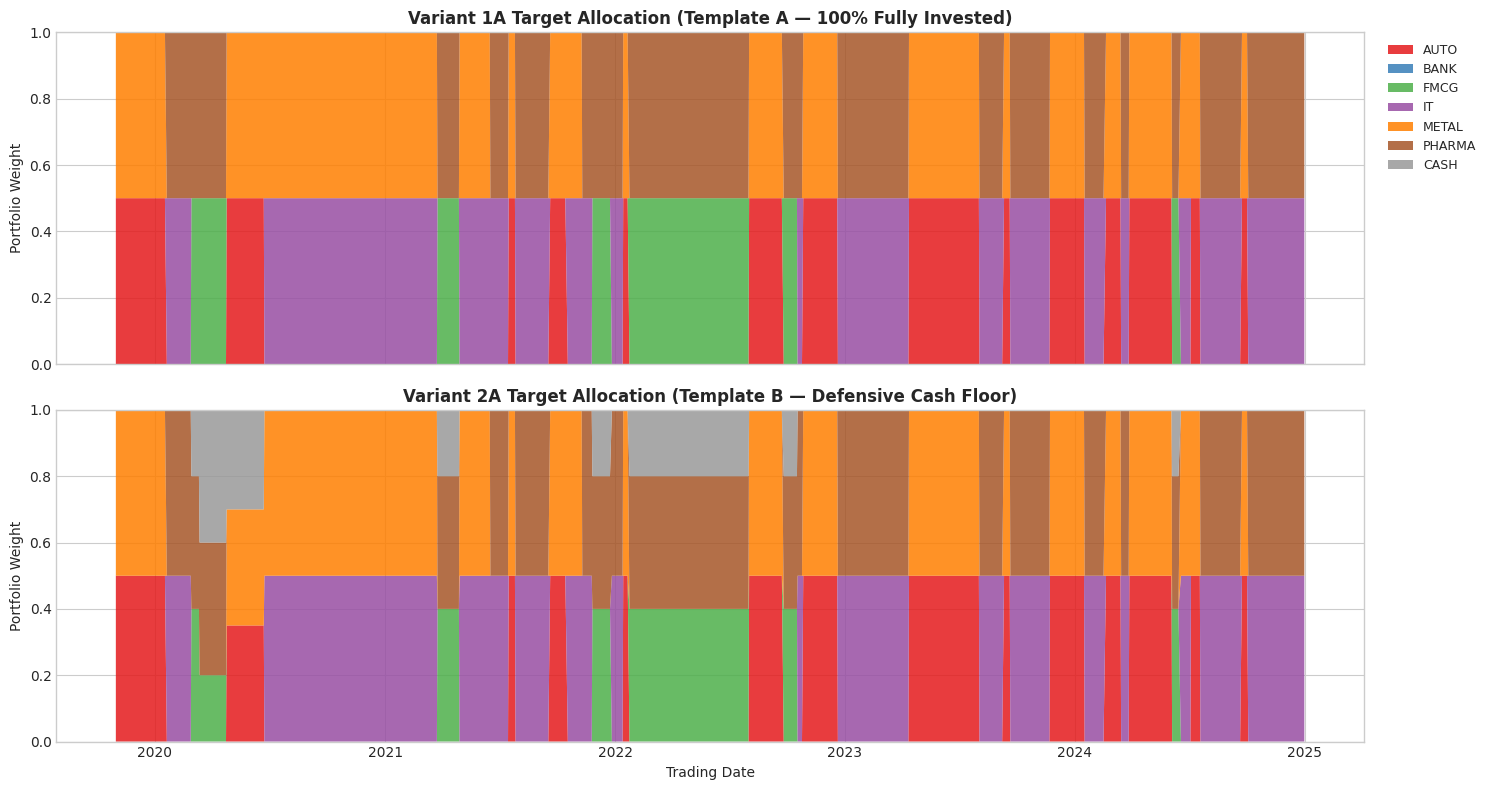

In [7]:
# Load genuine causal forward-filtered probabilities for training pool
prob_path = project_root / "results" / "regime_discovery" / "hmm_causal_probabilities.csv"
prob_df = pd.read_csv(prob_path, parse_dates=["Date"]).set_index("Date")
prob_cols = [f"prob_{j}" for j in range(6)]

# Strict training pool partition (2019-10-31 to 2024-12-31)
hmm_train = prob_df[prob_df["period"] == "train"][prob_cols].copy()
hmm_train = hmm_train.sort_index()

train_dates = hmm_train.index
print(f"Training Sessions Loaded: {len(train_dates)} (from {train_dates.min().date()} to {train_dates.max().date()})")

# Validation of continuous probability inputs
assert len(train_dates) == 1265, f"Expected exactly 1265 training dates, got {len(train_dates)}"
assert str(train_dates.min().date()) == "2019-10-31", f"Unexpected start date: {train_dates.min().date()}"
assert str(train_dates.max().date()) == "2024-12-31", f"Unexpected end date: {train_dates.max().date()}"
assert train_dates.is_monotonic_increasing, "Training dates are not monotonically increasing"

# Probability simplex assertions
p_arr = hmm_train[prob_cols].values
assert np.isfinite(p_arr).all(), "Non-finite probability values detected"
assert ((p_arr >= 0.0) & (p_arr <= 1.0)).all(), "Probabilities out of bounds [0, 1]"
row_sums = p_arr.sum(axis=1)
assert np.allclose(row_sums, 1.0, atol=1e-5), "Probability row sums deviate from 1.0"
print("Probability schema validated successfully (6 states, finite in [0, 1], sum to 1.0).")

# Run all 4 variants
schedules = {}
for v in ["1A", "1B", "2A", "2B"]:
    eng = RegimeRotationRulesEngine(variant=v)
    sched = eng.generate_schedule(train_dates, hmm_train, price_df=price_df)
    schedules[v] = sched
    rebalances = int(sched["rebalance_triggered"].sum())
    avg_turnover = float(sched["turnover"].mean() * 100.0)
    print(f"Variant {v:<2}: Total Rebalances = {rebalances:3d} | Mean Daily Turnover = {avg_turnover:.2f}%")

# Plot allocation timeline ribbon for Variant 1A and Variant 2A
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

sched_1a = schedules["1A"]
weight_cols = [f"w_{s}" for s in SECTOR_NAMES] + ["w_CASH"]
colors = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628", "#999999"]

axes[0].stackplot(sched_1a.index, [sched_1a[c] for c in weight_cols], labels=SECTOR_NAMES + ["CASH"], colors=colors, alpha=0.85)
axes[0].set_title("Variant 1A Target Allocation (Template A — 100% Fully Invested)", fontweight="bold")
axes[0].set_ylabel("Portfolio Weight")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9)
axes[0].set_ylim(0, 1.0)

sched_2a = schedules["2A"]
axes[1].stackplot(sched_2a.index, [sched_2a[c] for c in weight_cols], labels=SECTOR_NAMES + ["CASH"], colors=colors, alpha=0.85)
axes[1].set_title("Variant 2A Target Allocation (Template B — Defensive Cash Floor)", fontweight="bold")
axes[1].set_ylabel("Portfolio Weight")
axes[1].set_xlabel("Trading Date")
axes[1].set_ylim(0, 1.0)

plt.tight_layout()
plt.show()


## 7. Verification & Automated Test Coverage

All 21 requirements of the Phase 8 & Phase 9.1 rules engine specification are formally verified by the automated test suite in `tests/test_regime_rotation_rules.py`.

| Requirement # | Test Name | Status |
| :---: | :--- | :---: |
| 1 | `test_r0_r5_allocation_mapping` | **PASSED** |
| 2 | `test_all_four_strategy_variants` | **PASSED** |
| 3 | `test_exact_agreed_equal_weighted_allocations` | **PASSED** |
| 4 | `test_inverse_volatility_weights_calculation` | **PASSED** |
| 5 | `test_volatility_floor_behavior` | **PASSED** |
| 6 | `test_confidence_threshold_acceptance_and_rejection` | **PASSED** |
| 7 | `test_missing_and_invalid_probabilities` | **PASSED** |
| 8 | `test_boundary_ties_and_incumbent_persistence` | **PASSED** |
| 9 | `test_retaining_previous_weights_on_low_confidence` | **PASSED** |
| 10 | `test_nifty50_initialization` | **PASSED** |
| 11 | `test_first_transition_turnover_and_cost` | **PASSED** |
| 12 | `test_next_day_close_execution_timing` | **PASSED** |
| 13 | `test_five_day_minimum_holding_period` | **PASSED** |
| 14 | `test_r3_crisis_bypass_without_same_day_execution` | **PASSED** |
| 15 | `test_weights_simplex_constraint_across_entire_schedule` | **PASSED** |
| 16 | `test_no_future_return_leakage_in_volatility` | **PASSED** |
| 17 | `test_deterministic_behavior` | **PASSED** |
| 18 | `test_continuous_probability_precedence_over_regime_id` | **PASSED** |
| 19 | `test_continuous_probability_confidence_threshold_filtering` | **PASSED** |
| 20 | `test_malformed_continuous_probability_vectors_rejected` | **PASSED** |
| 21 | `test_recovered_hmm_causal_probabilities_file_ingestion` | **PASSED** |

> **Phase 9.1.5 Integration Complete:** Source module `src/regime_rotation_rules.py`, test suite `tests/test_regime_rotation_rules.py`, recovered probabilities `results/regime_discovery/hmm_causal_probabilities.csv`, and this demonstration notebook are fully synchronized.
